# 03 · Fenómeno 2: ¿de dónde sale la "receta"?
**Pregunta.** Dentro de un mismo producto con destino al Skinpass, ¿cambia la temperatura objetivo de enrollado entre rollos, y qué explica ese cambio?

**Por qué importa.** Si la consigna cambia porque cambia el cliente, comparar rollos a 580 °C contra 620 °C es comparar especificaciones distintas, no el efecto de la temperatura (confusión por indicación). Si cambia en una fecha sin otro cambio, sería un experimento natural.

**Pasos**
1. Contar consignas distintas por producto (diagnóstico de soporte).
2. Medir qué parte de la variación de la consigna explica cada factor candidato.
3. Revisar casos concretos por cliente y por mes.
4. Comparar consigna contra temperatura real.

## 0. Configuración
En Colab, el notebook clona el repositorio privado con un token guardado en **Secretos** (`GITHUB_TOKEN`) e instala el lector rápido de Excel. En local solo importa `src/ternium.py`, donde viven la carga de datos y las reglas de limpieza.

In [1]:
# Configuración: el mismo notebook corre en Colab y en local.
import os, sys
if 'google.colab' in sys.modules:
    from google.colab import userdata
    token = userdata.get('GITHUB_TOKEN')   # Colab: icono de llave > Secretos > GITHUB_TOKEN
    if not os.path.exists('/content/Entregable_Reto'):
        !git clone -q https://{token}@github.com/DiegoLarrieta/Entregable_Reto.git /content/Entregable_Reto
    %pip install -q python-calamine
    os.chdir('/content/Entregable_Reto/notebooks')
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.ternium import *

estilo()
pd.set_option('display.max_columns', 20)

In [2]:
df = aplicar_reglas(cargar_mc4())
s = df[df.SKP & df['Temp Enrollado Obj'].notna()]
print(f'{len(s):,} rollos con destino al Skinpass y consigna registrada')

50,015 rollos con destino al Skinpass y consigna registrada


## 1. ¿En cuántos productos cambia la consigna?
Solo tomamos productos con más de 200 rollos, para que la comparación tenga muestra.

In [3]:
g = s.groupby('Producto')['Temp Enrollado Obj'].agg(rollos='size', consignas='nunique')
grandes = g[g.rollos > 200]
varias = grandes[grandes.consignas > 1].index
x = s[s.Producto.isin(varias)].copy()

print(f'Productos con >200 rollos:             {len(grandes)}')
print(f'De ellos, con más de una consigna:     {len(varias)} ({len(x):,} rollos)')
print('Consignas más comunes en esos productos:', x['Temp Enrollado Obj'].value_counts().head(3).to_dict())

Productos con >200 rollos:             65
De ellos, con más de una consigna:     30 (12,871 rollos)
Consignas más comunes en esos productos: {620.0: 3483, 580.0: 3363, 550.0: 1942}


**Qué vemos.** Cerca de la mitad de los productos grandes reciben dos o tres temperaturas objetivo, típicamente 580 y 620 °C. Hay variación; falta saber de dónde viene.

## 2. ¿Qué explica la consigna?
Para cada factor calculamos qué fracción de la variación de la consigna **dentro de producto** desaparece si conocemos ese factor. 100% significa que el factor la determina por completo.

In [4]:
factores = {'PRAM': 'PRAM (práctica)', 'Subnorma': 'Subnorma', 'Orden': 'Orden*', 'Programa': 'Programa*',
            'Grado Planchón': 'Grado planchón', 'PRO': 'PRO', 'Cliente': 'Cliente',
            'Criticidad Temperatura Objetivo': 'Criticidad temp.', 'Mes': 'Mes', 'Uso General': 'Uso general'}

y = x['Temp Enrollado Obj']
dentro = y - y.groupby(x.Producto).transform('mean')   # variación que queda dentro de producto
filas = []
for col, etiqueta in factores.items():
    celda = x.Producto + '#' + x[col].astype(str)
    resto = y - y.groupby(celda).transform('mean')
    filas.append({'factor': etiqueta,
                  'explica': 1 - (resto ** 2).sum() / (dentro ** 2).sum(),
                  'niveles': x.groupby('Producto')[col].nunique().mean()})
r = pd.DataFrame(filas).sort_values('explica')
print(f"Cada PRAM tiene una sola consigna en todo el año: {(df.groupby('PRAM')['Temp Enrollado Obj'].nunique() <= 1).mean():.0%} de los PRAM")
r.sort_values('explica', ascending=False).round(2)

Cada PRAM tiene una sola consigna en todo el año: 100% de los PRAM


,factor,explica,niveles
0,PRAM (práctica),1.00,2.73
2,Orden*,0.99,104.90
1,Subnorma,0.94,1.23
3,Programa*,0.92,135.40
4,Grado planchón,0.63,3.07
5,PRO,0.57,8.23
6,Cliente,0.54,11.20
7,Criticidad temp.,0.31,1.40
8,Mes,0.27,11.63
9,Uso general,0.23,2.57


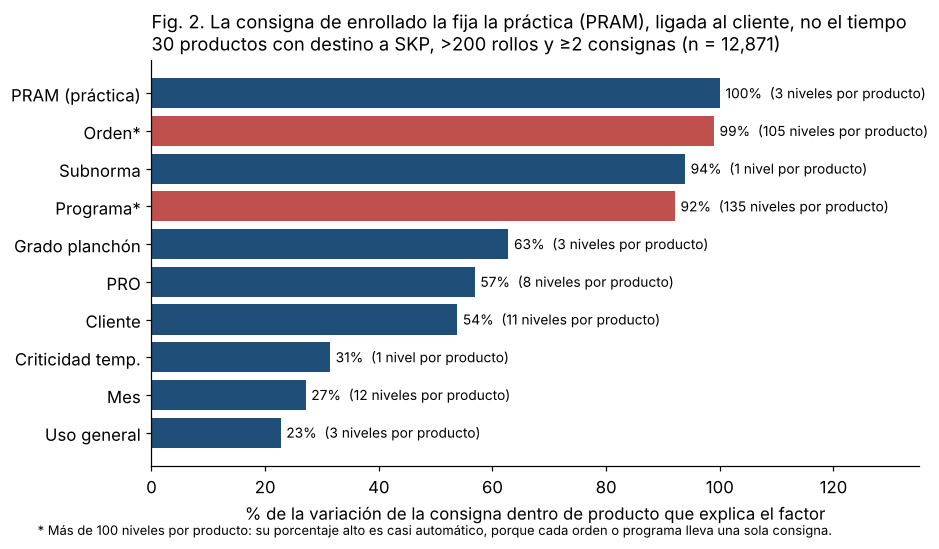

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.8))
colores = [COLORES['rojo'] if '*' in f else COLORES['azul'] for f in r.factor]
ax.barh(r.factor, r.explica * 100, color=colores)
for i, (e, n) in enumerate(zip(r.explica, r.niveles)):
    ax.text(e * 100 + 1, i, f'{e:.0%}  ({n:.0f} {"nivel" if round(n) == 1 else "niveles"} por producto)', va='center', fontsize=9)
ax.set_xlim(0, 135)
ax.set_xlabel('% de la variación de la consigna dentro de producto que explica el factor')
ax.set_title(f'Fig. 2. La consigna de enrollado la fija la práctica (PRAM), ligada al cliente, no el tiempo\n'
             f'{len(varias)} productos con destino a SKP, >200 rollos y ≥2 consignas (n = {len(x):,})')
fig.text(0.01, -0.02, '* Más de 100 niveles por producto: su porcentaje alto es casi automático, porque cada orden o programa lleva una sola consigna.', fontsize=8.5)
guardar(fig, 'fig2_receta')
plt.show()

**Cómo leerla.** Cada barra dice cuánto de la diferencia de consignas dentro de un producto se explica al saber ese factor. Las barras rojas tienen tantos niveles que su valor alto no dice nada.

**Qué vemos.** La práctica de proceso (PRAM) explica el 100%: cada PRAM tiene una sola temperatura en todo el año, así que **el PRAM es la receta**. La Subnorma y el cliente explican mucho; el mes, poco. La consigna cambia porque cambia la especificación del pedido, no porque la planta la haya ajustado en el tiempo.

## 3. Casos concretos

In [6]:
for p in ['SAE J403 | 1006 | (1.5, 2.0]', 'ASTM A 1011 | CS TIPO B | (3.0, 4.0]']:
    caso = x[x.Producto == p]
    print('\n', p)
    print(pd.crosstab(caso.Cliente, caso['Temp Enrollado Obj']).to_string())


 SAE J403 | 1006 | (1.5, 2.0]
Temp Enrollado Obj              580.0  620.0
Cliente                                     
ACEROS VS                           5      0
ACEROTECA TRADING                  14      3
ALMACENADORA AFIRME, SOCIEDAD       3      0
CALENTADORES DE AMERICA            38      0
GALVASID                            0    731
GRUPO INDUSTRIAL CH DE TLAXCAL     12      0
INDUSTRIAS TUGAL                    0      4
LAMINA DESPLEGADA                  22      2
METALES DESPLEGADOS                 1      0
RGF MANUFACTURING                   2      0
STEEL TECHNOLOGIES DE MEXICO       15      0

 ASTM A 1011 | CS TIPO B | (3.0, 4.0]
Temp Enrollado Obj              580.0  620.0
Cliente                                     
ABINSA SA DE CV                     0     10
CASTLE METALS DE MEXICO             0      3
COILPLUS MEXICANA                   0     16
CURTIS STEEL COMPANY, LLC           0      2
FERRUMAJA                           0      7
Farwest Steel Corporation     

**Qué vemos.** En SAE J403 1006 de 1.5 a 2 mm, el cliente GALVASID recibió sus 731 rollos a 620 °C y casi todos los demás a 580 °C. El cambio aparente en ASTM A1011 CS Tipo B a partir de julio resultó ser un cliente nuevo (TRINITY) con su propio PRAM, no un cambio de receta. TRINITY sí recibió el mismo producto con dos PRAM distintos: es el único contraste dentro de un mismo cliente.

## 4. ¿Se cumple la consigna?

In [7]:
x['error_C'] = x['Temp Enrollado Real'] - x['Temp Enrollado Obj']
x.groupby('Temp Enrollado Obj').error_C.describe()[['count', '25%', '50%', '75%']].round(1)

,count,25%,50%,75%
Temp Enrollado Obj,,,,
400.0,1.0,-7.4,-7.4,-7.4
500.0,57.0,-7.3,-2.8,-0.4
520.0,34.0,-10.3,-7.1,-5.8
550.0,1942.0,-6.5,-3.5,-1.0
560.0,222.0,-3.5,-1.5,0.2
580.0,3363.0,-6.8,-4.0,-1.5
600.0,962.0,-4.8,-2.5,-0.5
620.0,3483.0,-5.7,-3.3,-1.3
640.0,1575.0,-4.8,-3.2,-1.3


**Qué vemos.** La temperatura real queda en mediana a pocos grados de la consigna en todos los niveles. El seguimiento es estrecho, así que la variación "natural" alrededor del objetivo es muy pequeña para estudiar efectos de temperatura.

## Implicaciones para el análisis
1. Cualquier efecto de la consigna debe estimarse **dentro de cliente o de PRAM**, no dentro de producto.
2. Dentro de un PRAM no hay variación de consigna: no hay soporte para estimar su efecto. Lo único aprovechable es la desviación real-objetivo (pocos grados) y los pocos clientes con dos PRAM.
3. La temperatura real es un **mediador** (consigna → temperatura real → óxido): si se estudia la consigna, no se ajusta por la temperatura real.
4. PRAM y Subnorma van en el diagrama causal como causas comunes de la consigna y del resultado.